# Practice Session 06: Network models


In this session we will learn to use [NetworkX](https://networkx.github.io/), a Python package, and we will write code to create random graphs and preferential attachment graphs.

**Note:** The graph generators we ask you to delive for this practice are already implemented in the NetworkX library and in other places online. *Do not copy those implementations:* they reproduce the same kinds of graph but follow a design that is different from what we describe here.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Author: <font color="blue">Martí Pascual Barluenga</font>

E-mail: <font color="blue">marti.pascual01@estudiant.upf.edu</font>

Date: <font color="blue">6/11/2024</font>

# 1. Random (ER) graph generator

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import itertools

from collections import OrderedDict

In [2]:
# Leave as-is

def flip_coin(p):
    if np.random.random() < p:
        return True
    else:
        return False

## 1.1. Generate ER graph

In [3]:
def generate_random_graph(N, p):
    g = nx.Graph()

    for i in range(N):
        g.add_node(i)
    
    for u, v in itertools.combinations(g.nodes, 2):
        if flip_coin(p):
            g.add_edge(u, v)
    
    return g

In [4]:
N = 100  # Number of nodes
p = 0.1  # Connection probability
trials = 1000  # Number of graphs to generate

observed_edges = []

# Generate 1000 graphs and count the number of edges
for _ in range(trials):
    g = generate_random_graph(N, p)
    observed_edges.append(g.number_of_edges())

# Calculate the expected number of edges
expected_edges = p * (N * (N - 1)) / 2


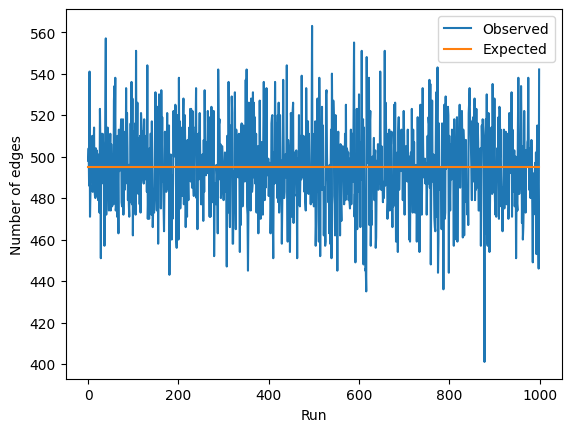

In [5]:
# Leave as-is

plt.xlabel("Run")
plt.ylabel("Number of edges")
plt.plot(range(trials), observed_edges, label="Observed")
plt.plot(range(trials), [expected_edges] * trials, label="Expected")
plt.legend()
plt.show()

In [6]:
def generate_random_graph_avg_degree(N, kavg):
    # Calculate the probability p using the formula:
    p = kavg / (N - 1)
    # Generate the random graph using the calculated probability p
    return generate_random_graph(N, p)


In [7]:
def graph_average_degree(g):
    return sum(dict(g.degree()).values()) / g.number_of_nodes()

# Parameters
N = 3000
target_average_degrees = np.arange(0.0, 3.1, 0.1)

observed_average_degrees = []

for target_average_degree in target_average_degrees:
    g = generate_random_graph_avg_degree(N, target_average_degree)
    observed_average_degree = graph_average_degree(g)
    observed_average_degrees.append(observed_average_degree)


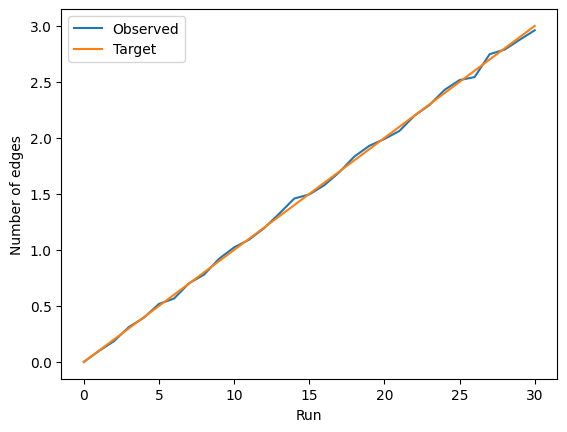

In [8]:
# Leave as-is
plt.xlabel("Run")
plt.ylabel("Number of edges")
plt.plot(range(len(target_average_degrees)), observed_average_degrees, label="Observed")
plt.plot(range(len(target_average_degrees)), target_average_degrees, label="Target")
plt.legend()
plt.show()

## 1.2. Measure connectivity


In [9]:
def is_connected(g):
    # Get the list of all nodes in the graph
    nodes = list(g.nodes)
    
    # Iterate over all pairs of nodes
    for u, v in itertools.combinations(nodes, 2):
        # Check if there is a path between node u and node v
        if not nx.has_path(g, u, v):
            # If any pair of nodes is not connected, return False
            return False
    
    # If all pairs of nodes are connected, return True
    return True

In [10]:
# Leave as-is

def size_largest_cc(G):
    
    # Obtain the list of connected components of the graph sorted from largest to smallest
    Gcc = sorted(nx.connected_components(G), key=len, reverse=True)
    
    # Selects the first connected component in that list
    G0 = G.subgraph(Gcc[0])
    
    # Returns its number of nodes
    return G0.number_of_nodes()

In [11]:
N = 1000
target_average_degrees = np.arange(0.2, 2.0, 0.05)

largest_cc_sizes = []
average_degrees = []

for target_average_degree in target_average_degrees:
    
    # Generate graph
    g = generate_random_graph_avg_degree(N, target_average_degree)
    assert g.number_of_nodes() == N, "Wrong number of nodes"
    
    # Obtain observed average degree
    average_degree = graph_average_degree(g)
    graph_average_degree(g)
    average_degree = graph_average_degree(g)
    average_degrees.append(average_degree)
    
    # Obtain size of largest connected component as a fraction of the total number of nodes
    largest_cc_size = size_largest_cc(g) / N
    largest_cc_sizes.append(largest_cc_size)

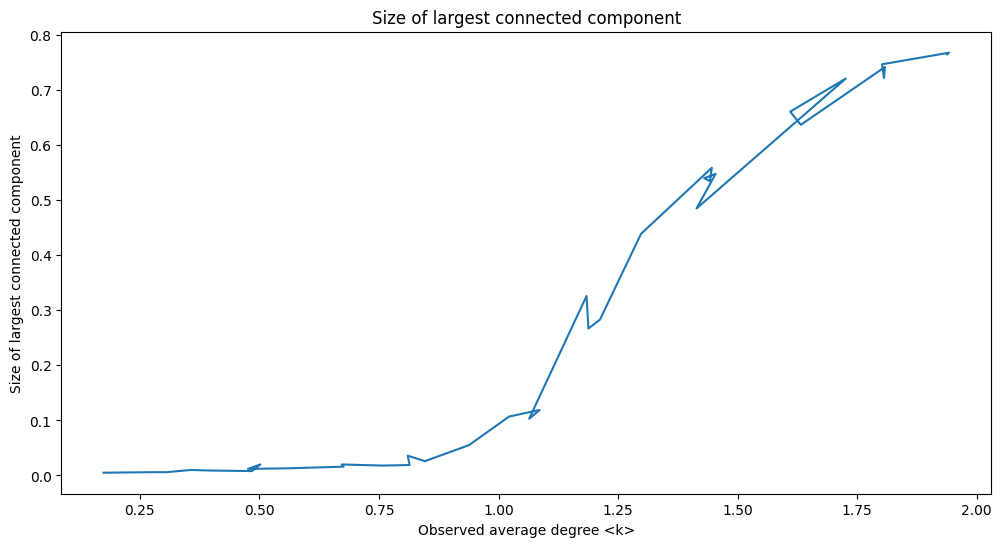

In [12]:
# LEAVE AS-IS

plt.figure(figsize=(12,6))
plt.plot(average_degrees, largest_cc_sizes)
plt.title("Size of largest connected component")
plt.xlabel("Observed average degree <k>")
plt.ylabel("Size of largest connected component")
plt.show()

1.In theory, for random ER graphs, the largest component typically emerges near an average degree of 1. Below this value, most nodes are in small and  isolated components, but as the average degree surpasses 1, a giant component appears and starts growing.

2.In this case, we observe that the plot closely aligns with the theory, showing that just after reaching an average degree of 1, the size of the largest connected component increases drastically.

3.The curve showing the size of the largest component as a function of average degree can have a non-univalent behavior because of changes in connectivity for randomness in edge formation. It is not a function because in some cases for a single x value there are two y values witch means it is not a function.

## 1.3. Visualize graphs and plot degree distributions

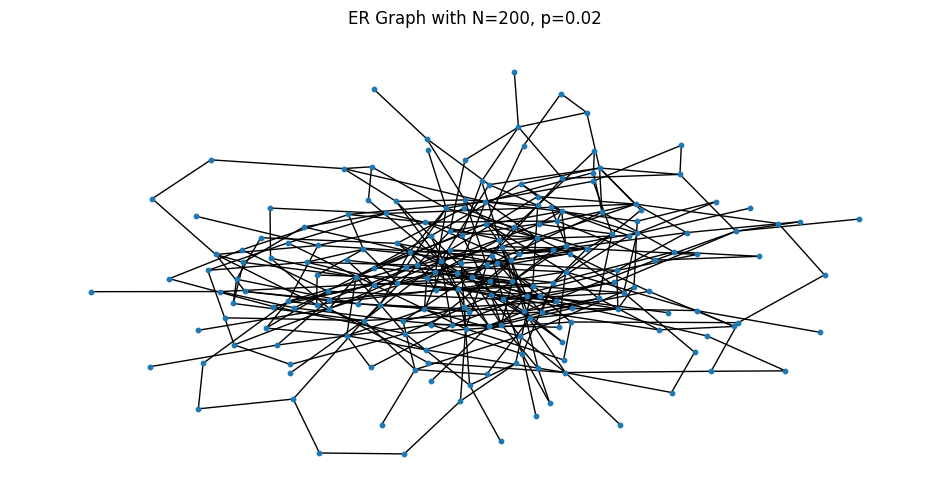

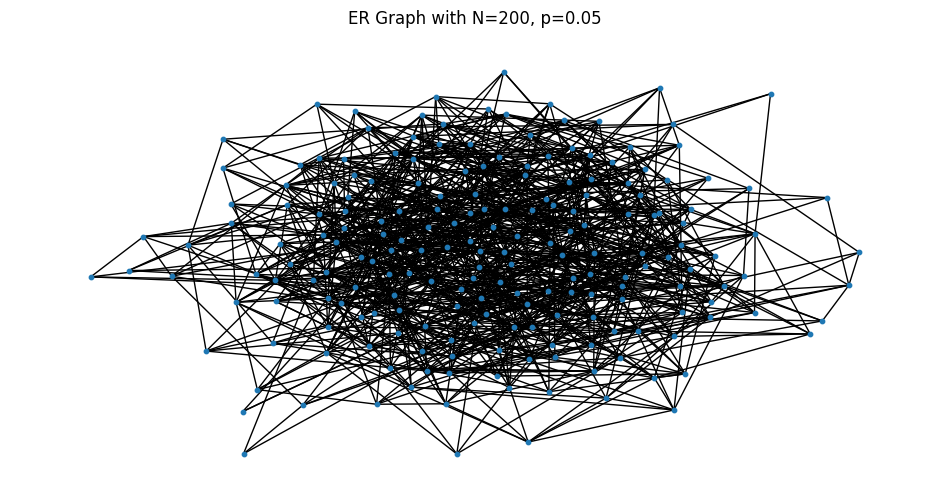

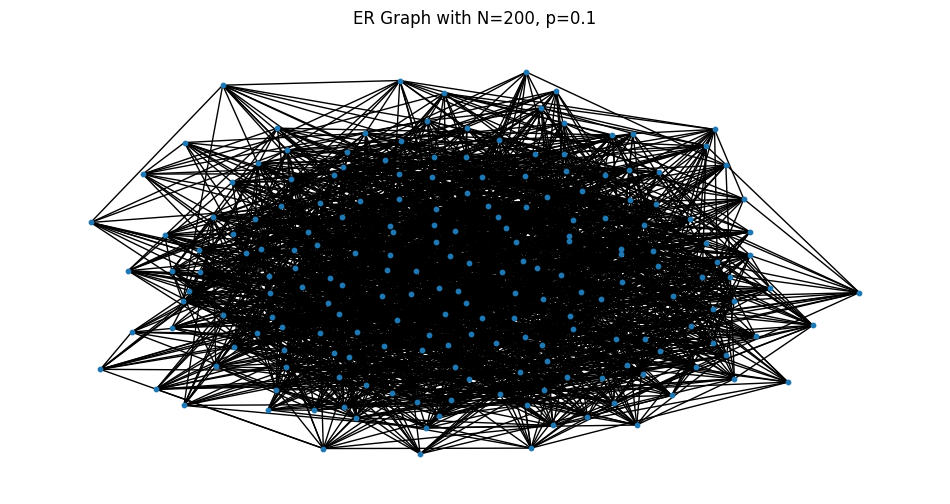

In [13]:
def generate_and_visualize_er_graphs(N, p_values):
    for p in p_values:
        while True:
            g = generate_random_graph(N, p)
            if is_connected(g):
                break
        plt.figure(figsize=(12, 6))
        plt.axis('off')
        pos = nx.spring_layout(g)
        nx.draw_networkx(g, pos, with_labels=False, node_size=10)
        plt.title(f"ER Graph with N={N}, p={p}")
        plt.show()

# Parameters
N = 200
p_values = [0.02, 0.05, 0.1]

# Generate and visualize 3 ER graphs
generate_and_visualize_er_graphs(N, p_values)

In [14]:
def print_er_statistics(g, p):
    N = g.number_of_nodes()
    observed_avg_degree = graph_average_degree(g)
    expected_avg_degree = p * (N - 1)
    
    print(f"Observed average degree: {observed_avg_degree}")
    print(f"Expected average degree: {expected_avg_degree}")

# Parameters
N = 200
p_values = [0.02, 0.05, 0.1]

# Generate and visualize 3 ER graphs and print their statistics
for p in p_values:
    while True:
        g = generate_random_graph(N, p)
        if is_connected(g):
            break
    

    print(f"ER Graph with N={N}, p={p}")
    print_er_statistics(g, p)

ER Graph with N=200, p=0.02
Observed average degree: 4.22
Expected average degree: 3.98
ER Graph with N=200, p=0.05
Observed average degree: 10.39
Expected average degree: 9.950000000000001
ER Graph with N=200, p=0.1
Observed average degree: 19.98
Expected average degree: 19.900000000000002


In [15]:
# Leave as-is or modify if you want

def plot_degree_distribution(g):
    degree_dict = dict(g.degree())
    degree_ordered = OrderedDict(sorted(degree_dict.items(), key=lambda x: x[1], reverse=True))
    degree_sequence = list(degree_ordered.values())
    prob, bin_edges = np.histogram(degree_sequence, bins=range(1,np.max(degree_sequence)+2), density=True)
    plt.figure(figsize=(12,6))
    plt.loglog(bin_edges[:-1], prob, 'o-')
    plt.title("Probability density function")
    plt.xlabel("degree")
    plt.ylabel("probability")
    plt.autoscale(enable=True, axis='both')
    plt.show()

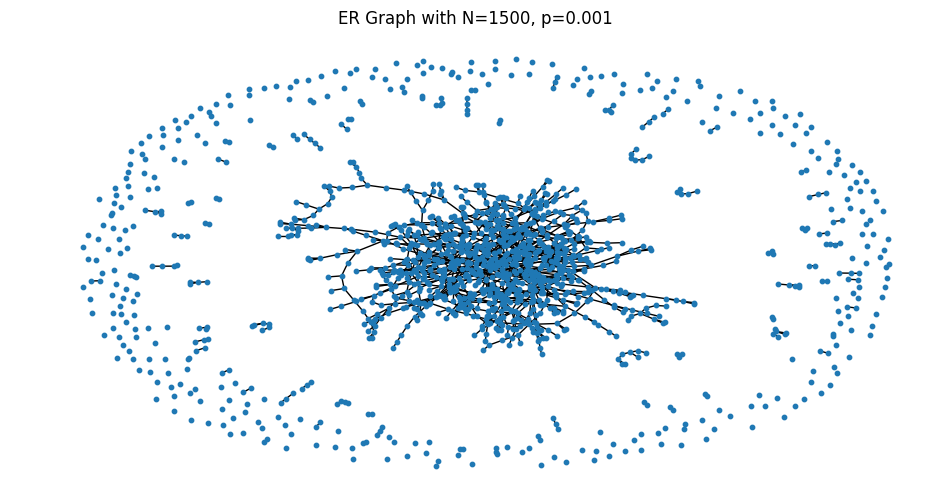

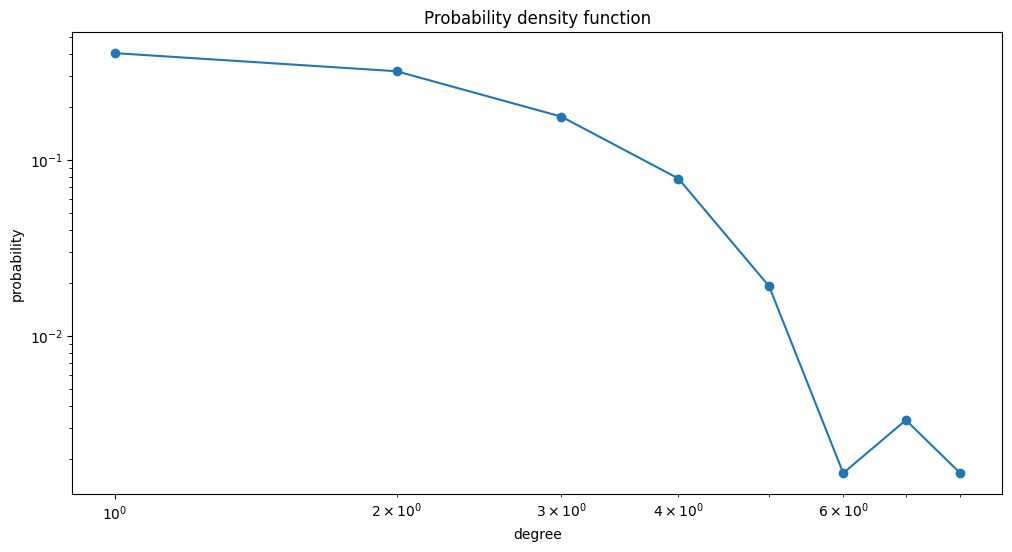

Graph with N=1500, p=0.001
Observed average degree: 1.6186666666666667
Expected average degree: 1.499




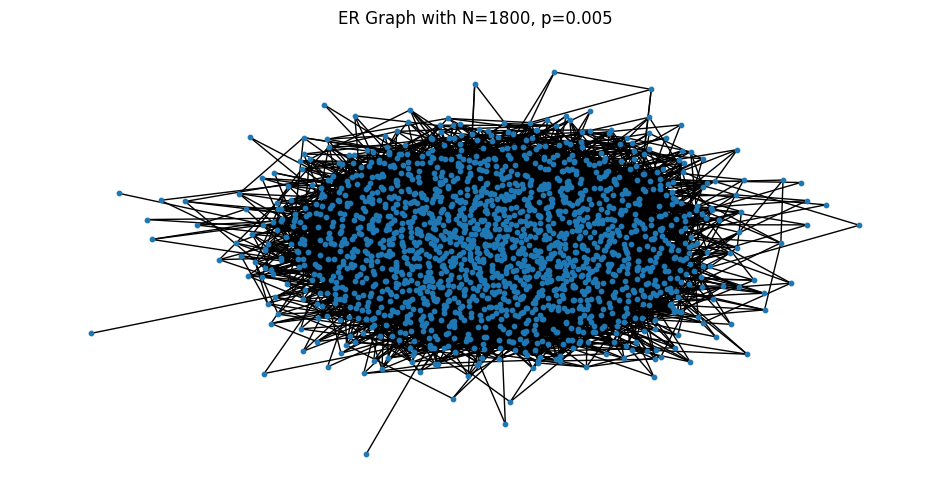

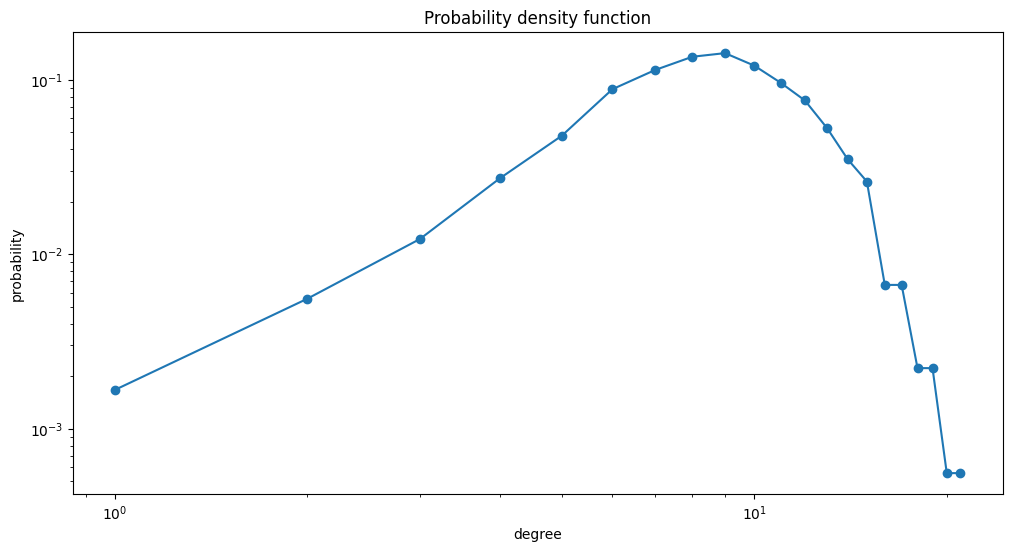

Graph with N=1800, p=0.005
Observed average degree: 9.157777777777778
Expected average degree: 8.995000000000001




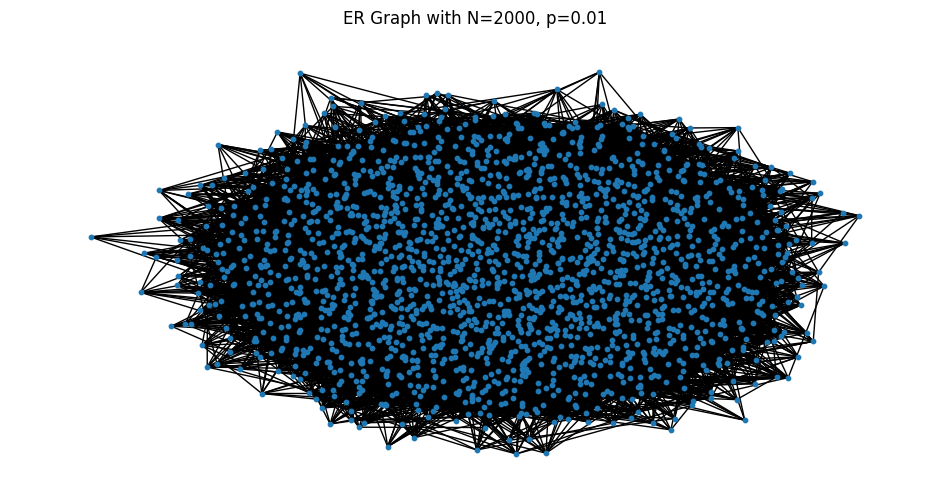

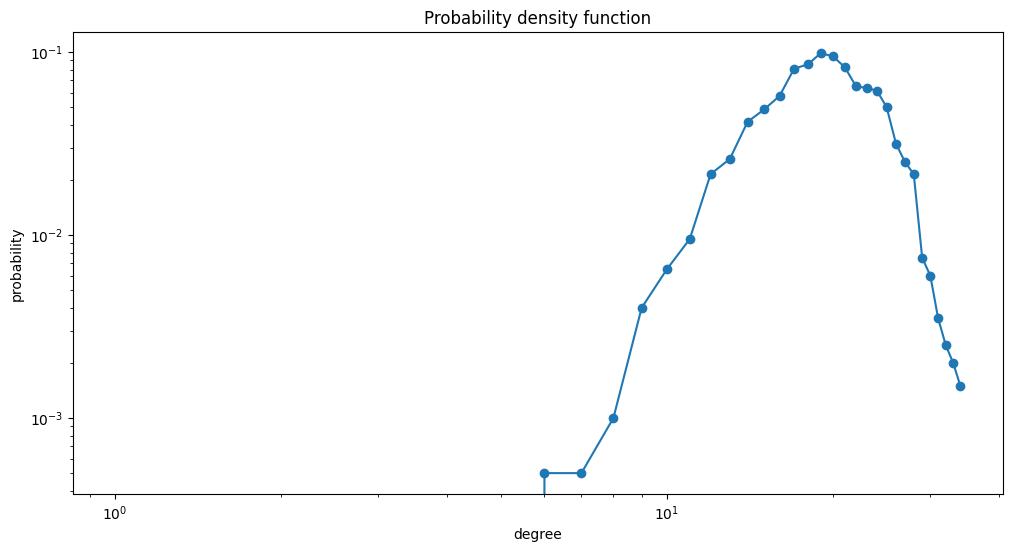

Graph with N=2000, p=0.01
Observed average degree: 19.87
Expected average degree: 19.990000000000002




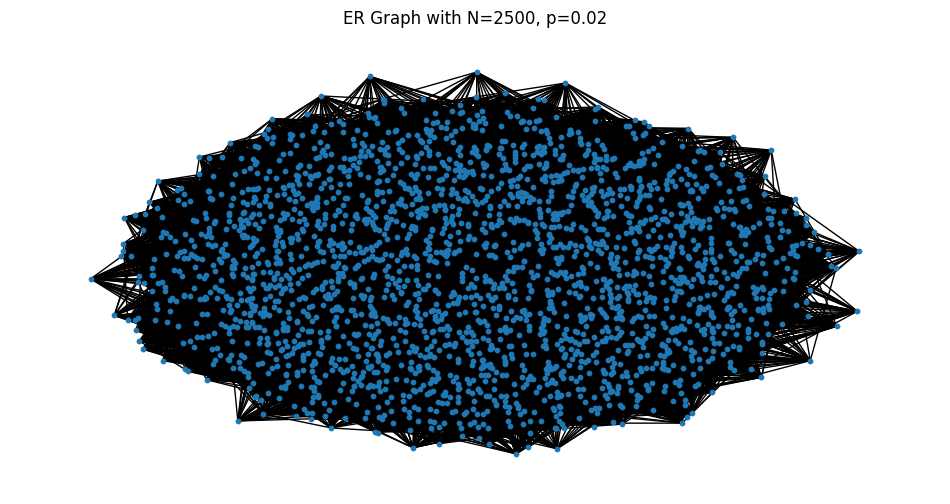

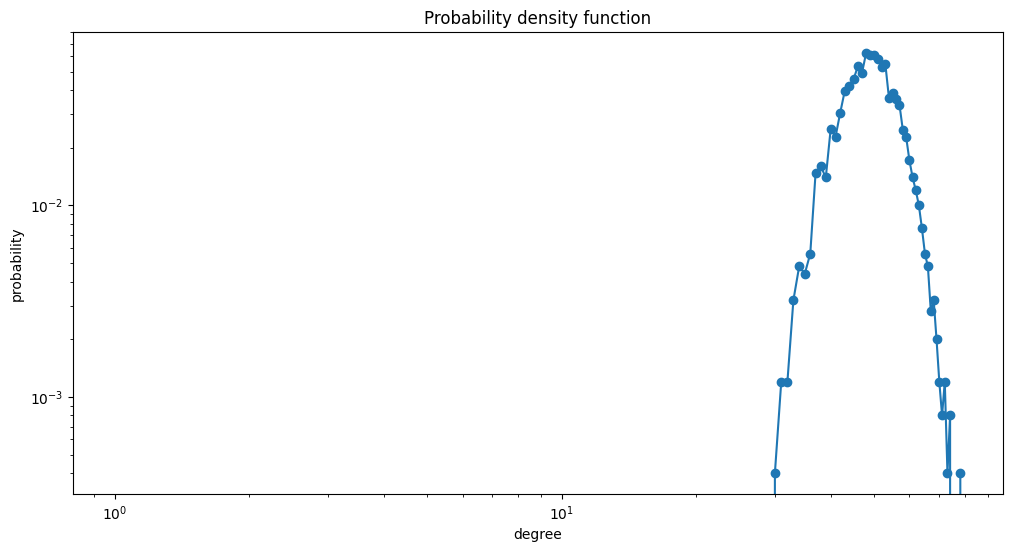

Graph with N=2500, p=0.02
Observed average degree: 49.7696
Expected average degree: 49.980000000000004




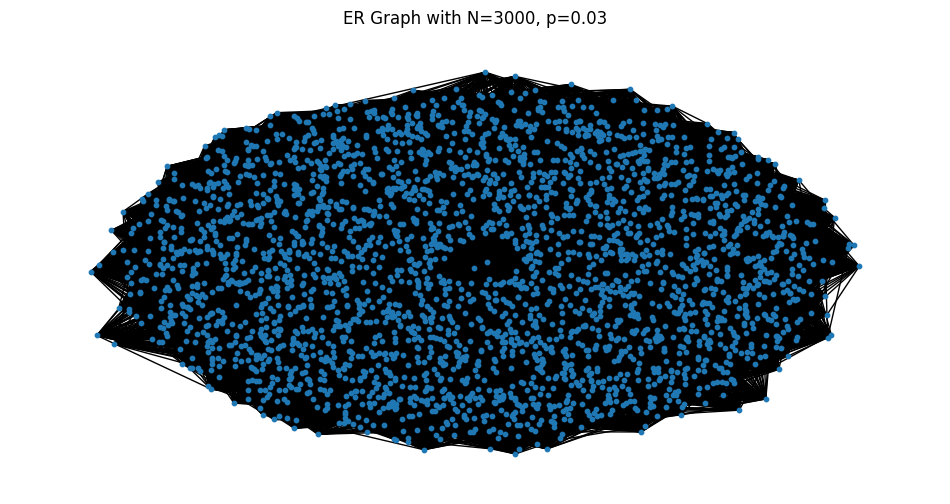

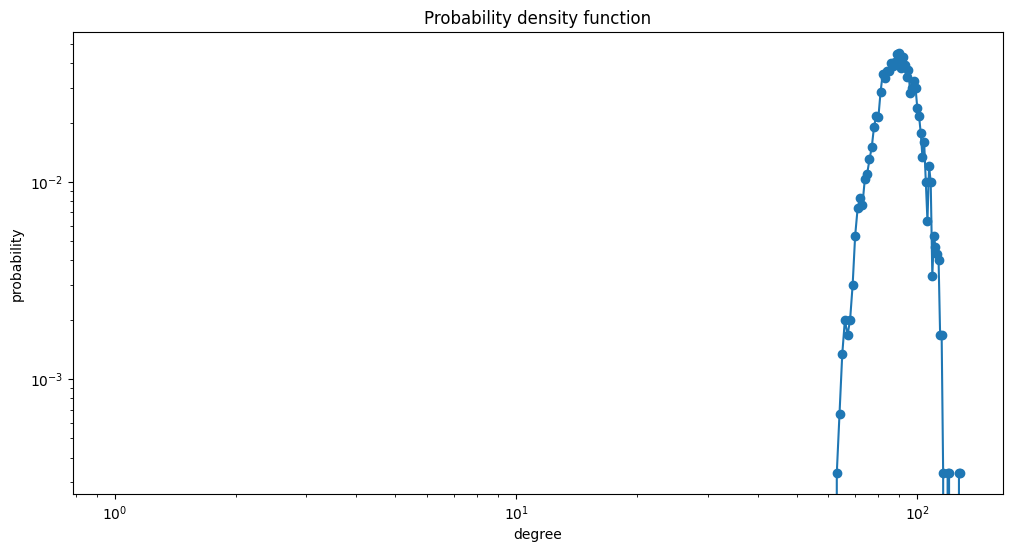

Graph with N=3000, p=0.03
Observed average degree: 90.03733333333334
Expected average degree: 89.97




In [16]:
def generate_and_visualize_er_graphs_with_distribution(N_values, p_values):
    for N, p in zip(N_values, p_values):
        g = generate_random_graph(N, p)
        
        # Visualize the graph
        plt.figure(figsize=(12, 6))
        plt.axis('off')
        pos = nx.spring_layout(g)
        nx.draw_networkx(g, pos, with_labels=False, node_size=10)
        plt.title(f"ER Graph with N={N}, p={p}")
        plt.show()
        
        # Plot degree distribution
        plot_degree_distribution(g)
        
        # Calculate and print average degree
        observed_avg_degree = graph_average_degree(g)
        expected_avg_degree = p * (N - 1)
        print(f"Graph with N={N}, p={p}")
        print(f"Observed average degree: {observed_avg_degree}")
        print(f"Expected average degree: {expected_avg_degree}")
        print("\n")

# Parameters
N_values = [1500, 1800, 2000, 2500, 3000]
p_values = [0.001, 0.005, 0.01, 0.02, 0.03]

# Generate and visualize 5 ER graphs with degree distribution
generate_and_visualize_er_graphs_with_distribution(N_values, p_values)

The figures show ER graphs with varying probabilities p  and their degree distributions. As  p  increases, the average degree rises, leading to denser graph structures. For low p values graphs are sparse with many isolated nodes. For p large, a connected component emerges, creating a denser structure. The degree distributions peak near the expected average degree, following a binomial distribution

# 2. Preferential attachment (BA) generator

In [17]:
# LEAVE AS-IS

def select_with_probability(x, m, p):
    return np.random.choice(x, size=m, replace=False, p=p)

In [18]:
# LEAVE AS-IS

trials = 1500
vector = ['a', 'b', 'c']
probabilities = [0.75, 0.13, 0.12]

all_selected = []
for i in range(trials):
    selected = select_with_probability(vector, 1, probabilities)[0]
    all_selected.append(selected)
    
for i, p in zip(vector, probabilities):
    print("Element {:s} was selected {:d} times, expected {:.0f}".format(i, all_selected.count(i), trials*p) )

Element a was selected 1125 times, expected 1125
Element b was selected 200 times, expected 195
Element c was selected 175 times, expected 180


In [19]:
def select_targets(g, m):
    # Check if feasible
    N = g.number_of_nodes()
    if N < m:
        raise ValueError('Graph has less than m nodes')

    # Compute sum of degree
    sum_degree = sum(dict(g.degree()).values())
    if sum_degree == 0:
        raise ValueError('Graph has no edges')

    # Compute probabilities
    probabilities = []
    for node, degree in g.degree():
        probabilities.append(degree / sum_degree)

    # Sample
    selected = select_with_probability(list(g.nodes), m, probabilities)

    return selected

In [20]:
def generate_preferential_attachment_graph(N, m0, m):
    # Check that m <= m0
    if m > m0:
        raise ValueError('m must be less than or equal to m0')
    
    # Create an empty graph
    g = nx.Graph()
    
    # Add nodes numbered from 0 to m0-1 to the graph
    for i in range(m0):
        g.add_node(i)
    
    # Create a cycle by linking node 0 to node 1, node 1 to node 2, ..., node m0-1 to node 0
    for i in range(m0):
        g.add_edge(i, (i + 1) % m0)
    
    # For every node u numbered from m0 to N-1
    for u in range(m0, N):
        # Select m targets for this node using select_targets
        targets = select_targets(g, m)
        
        # Add node u to the graph
        g.add_node(u)
        
        # Link each node u to each of the m targets
        for target in targets:
            g.add_edge(u, target)
    
    return g

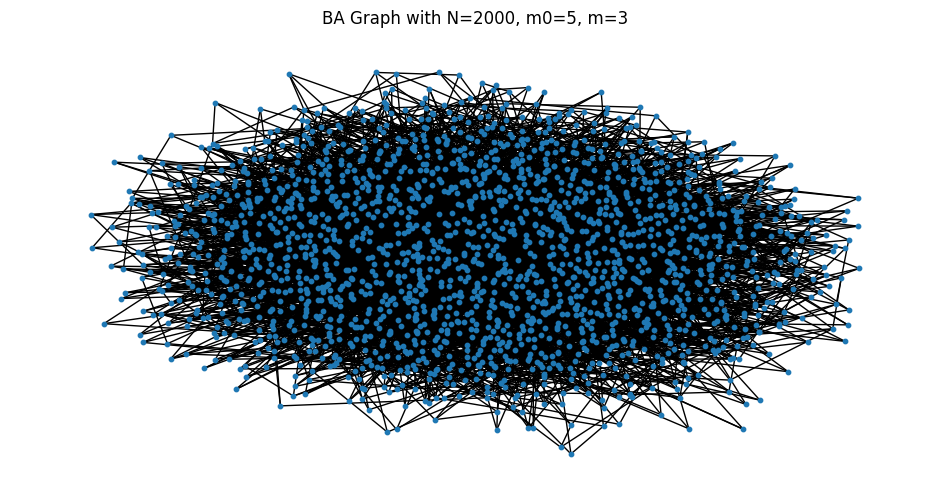

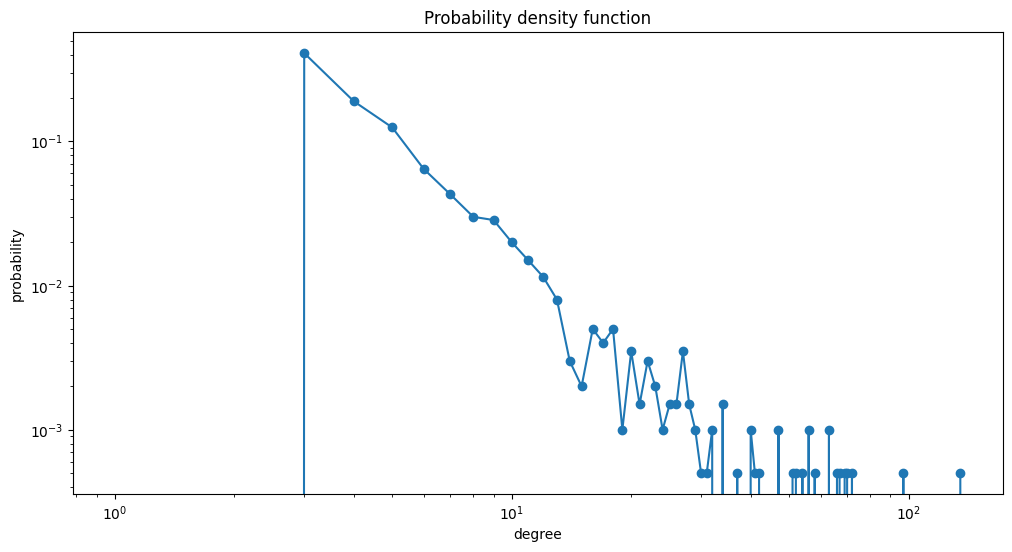

Graph with N=2000, m0=5, m=3
Observed average degree: 5.99
Expected average degree: 6




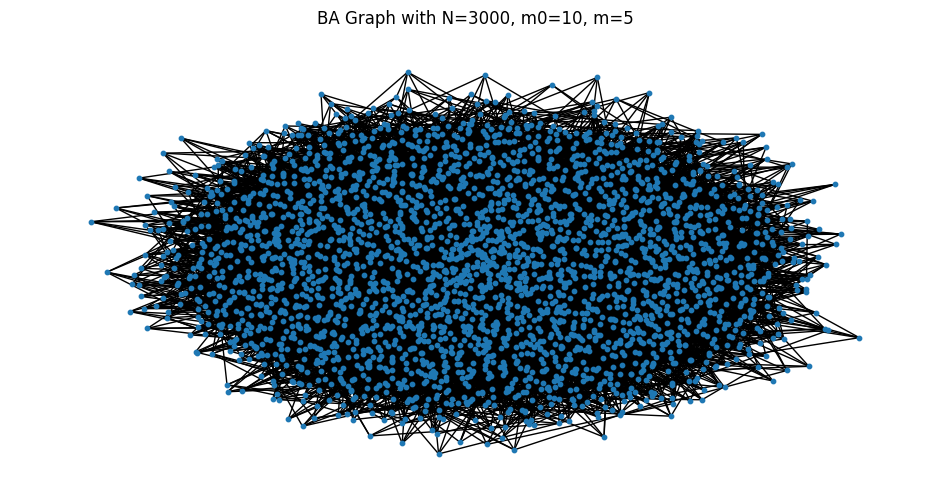

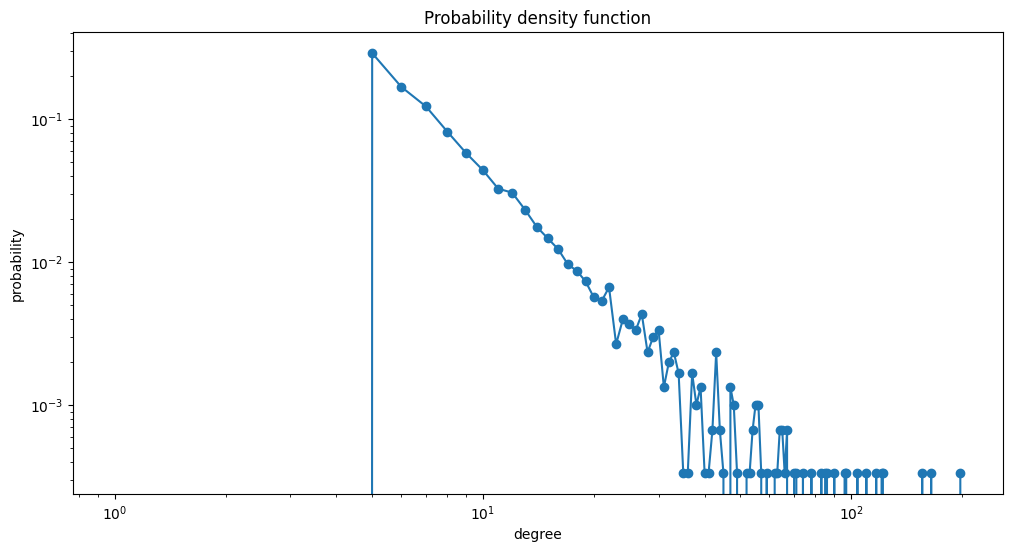

Graph with N=3000, m0=10, m=5
Observed average degree: 9.973333333333333
Expected average degree: 10




In [21]:
def generate_and_visualize_ba_graphs(N, m0, m):
    g = generate_preferential_attachment_graph(N, m0, m)
    
    # Visualize the graph
    plt.figure(figsize=(12, 6))
    plt.axis('off')
    pos = nx.spring_layout(g)
    nx.draw_networkx(g, pos, with_labels=False, node_size=10)
    plt.title(f"BA Graph with N={N}, m0={m0}, m={m}")
    plt.show()
    
    # Plot degree distribution
    plot_degree_distribution(g)
    
    # Calculate and print average degree
    observed_avg_degree = graph_average_degree(g)
    expected_avg_degree = 2 * m  # In BA model, the average degree is approximately 2m
    print(f"Graph with N={N}, m0={m0}, m={m}")
    print(f"Observed average degree: {observed_avg_degree}")
    print(f"Expected average degree: {expected_avg_degree}")
    print("\n")

# Parameters for the first BA graph
N1 = 2000
m0_1 = 5
m_1 = 3

# Parameters for the second BA graph
N2 = 3000
m0_2 = 10
m_2 = 5

# Generate and visualize the first BA graph
generate_and_visualize_ba_graphs(N1, m0_1, m_1)

# Generate and visualize the second BA graph
generate_and_visualize_ba_graphs(N2, m0_2, m_2)

The first BA graph with 3000 nodes and parameters m0 = 10 and m=5, shows a densely connected structure, with a few highly connected hub nodes, characteristic of a scale-free network. We can see how the observed average degree closely matches the expected average degree, 

The second BA graph has 2000 nodes with m0=5 and m=3. The network shows a similar pattern to the first graph, with several high-degree hubs. The degree distribution again follows a power-law, but with a lower average degree due to the smaller m value. 

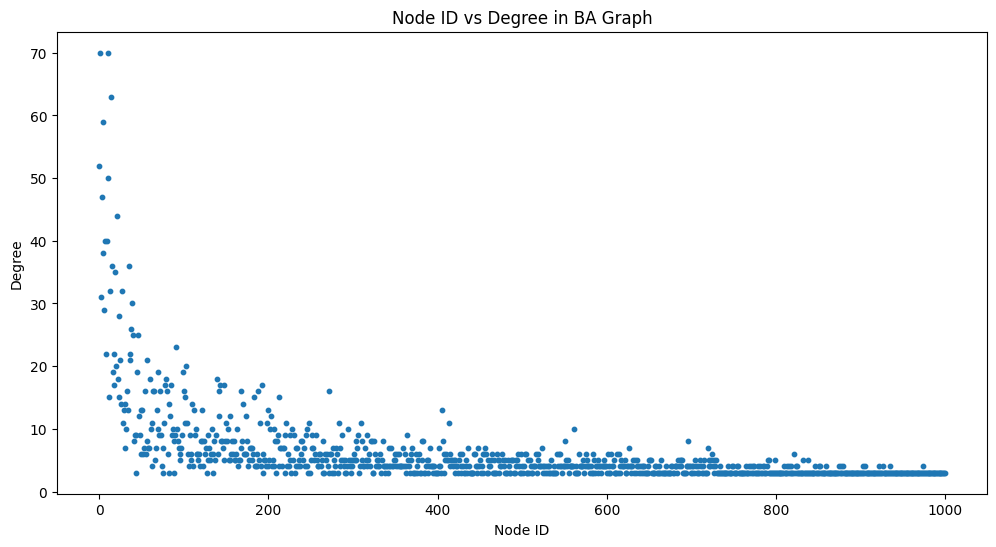

In [22]:
# Generate a BA graph with 1000 nodes
N = 1000
m0 = 5
m = 3
ba_graph = generate_preferential_attachment_graph(N, m0, m)

# Get the list of nodes and their degrees
nodes = list(ba_graph.nodes)
degrees = [ba_graph.degree(node) for node in nodes]

# Plot the node-id vs degree
plt.figure(figsize=(12, 6))
plt.scatter(nodes, degrees, s=10)
plt.xlabel("Node ID")
plt.ylabel("Degree")
plt.title("Node ID vs Degree in BA Graph")
plt.show()

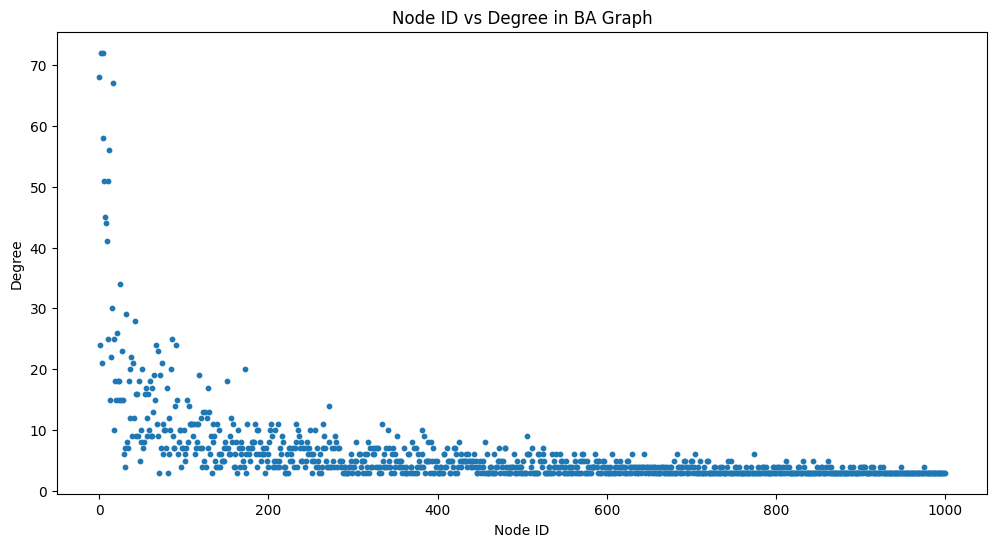

In [23]:
m0 = 5
m = 3
ba_graph = generate_preferential_attachment_graph(N, m0, m)

# Get the list of nodes and their degrees
nodes = list(ba_graph.nodes)
degrees = [ba_graph.degree(node) for node in nodes]

# Plot the node-id vs degree
plt.figure(figsize=(12, 6))
plt.scatter(nodes, degrees, s=10)
plt.xlabel("Node ID")
plt.ylabel("Degree")
plt.title("Node ID vs Degree in BA Graph")
plt.show()

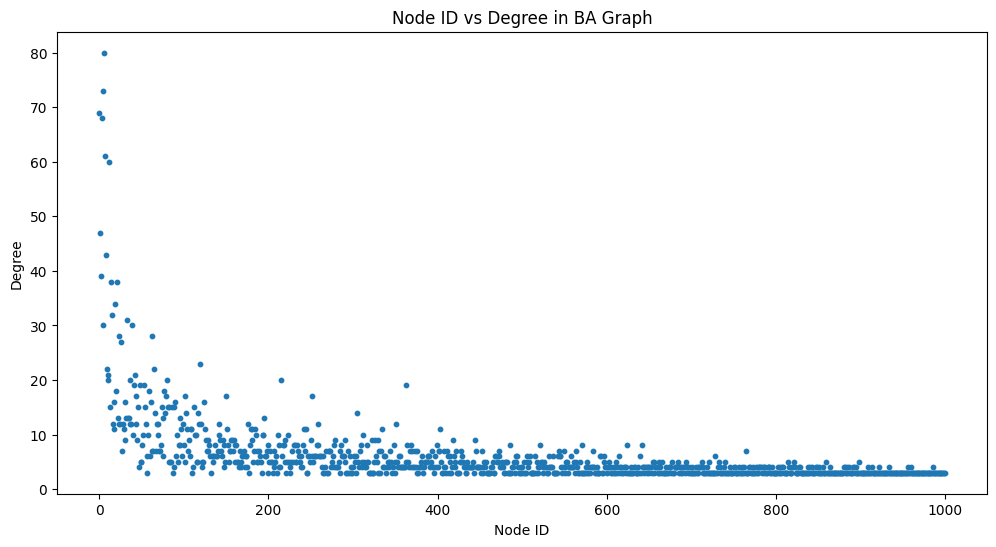

In [24]:
N = 1000
m0 = 5
m = 3
ba_graph = generate_preferential_attachment_graph(N, m0, m)

# Get the list of nodes and their degrees
nodes = list(ba_graph.nodes)
degrees = [ba_graph.degree(node) for node in nodes]

# Plot the node-id vs degree
plt.figure(figsize=(12, 6))
plt.scatter(nodes, degrees, s=10)
plt.xlabel("Node ID")
plt.ylabel("Degree")
plt.title("Node ID vs Degree in BA Graph")
plt.show()

We observe that a few nodes have significantly higher degrees, while most nodes have lower degrees. The graph shows the important property of BA networks, where new nodes are more likely to connect to highly connected nodes, creating a scale-free network with a few hubs. 

<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>